In [3]:
# Step 4a: Install dependencies and verify the hand-over from Notebook A
# What : Import the libraries, read data/processed/manifest.json and compare the md5 hash of
#        the parquet file.
# Why  : Both notebooks must use exactly the same data.
# Check: The cell prints 'handover ok'.

# run once per machine, then comment out
# %pip install pandas numpy duckdb pyarrow scikit-learn lightgbm xgboost matplotlib scipy
import os, json, hashlib, numpy as np, pandas as pd, warnings
warnings.filterwarnings('ignore')
m = json.load(open('data/processed/manifest.json'))
assert hashlib.md5(open(m['file'], 'rb').read()).hexdigest() == m['md5'], 'parquet differs from the manifest, rerun Notebook A'
os.makedirs('report', exist_ok=True); print('handover ok', m['rows'], 'rows')

handover ok 4727520 rows


In [4]:
# Step 4b: Feature table, targets and train / validation / test split
# What : Rerun sql/queries.sql, load the feat table, build the target (power 6 steps = 1
#        hour ahead), its delta, lag, rolling-mean, wind-direction and hour features, and
#        the farm-mean feature spatial_p (not a model input). Hold out every 4th turbine as
#        unseen; train on days up to 70%, validate on 70-80%, test after 80% on valid rows
#        with a valid target.
# Why  : The split decides whether the numbers can be trusted; the assert is the leakage
#        check.
# Check: Record the row counts of both sets and the number of features in the experiment
#        description.

import os, json, hashlib, numpy as np, pandas as pd, warnings
warnings.filterwarnings('ignore')
import duckdb
from lightgbm import LGBMRegressor
from sklearn.metrics import mean_absolute_error as MAE

con = duckdb.connect(); con.execute(open('sql/queries.sql').read())
base = con.execute("SELECT * FROM feat ORDER BY TurbID, step").df()

T_cols = ['Etmp', 'Itmp']
X_cols_no_temp = ['Patv', 'p_lag1', 'p_lag2', 'p_lag3', 'p_lag6', 'p_mean1h', 'Wspd', 'w_lag1', 'w_mean1h', 'wdir_sin', 'wdir_cos', 'Pab1', 'Prtv', 'hour_sin', 'hour_cos']
X_cols_temp = X_cols_no_temp + T_cols
HORIZON = 6

def table(d, clip=True, unknown=True, abnormal=True):
    d = d.copy()
    if clip: d['Patv'] = d.Patv.clip(lower=0)
    if unknown: d.loc[d.r_unknown == 1, 'Patv'] = np.nan
    if abnormal: d.loc[d.r_abnormal == 1, ['Patv', 'Wdir', 'Ndir']] = np.nan

    g = d.groupby('TurbID')
    d['y'] = g.Patv.shift(-HORIZON)
    d['y_delta'] = d['y'] - d.Patv

    for k in [1, 2, 3, 6]: d['p_lag%d' % k] = g.Patv.shift(k)
    d['p_mean1h'] = g.Patv.transform(lambda s: s.rolling(6, min_periods=6).mean()); d['w_lag1'] = g.Wspd.shift(1)
    d['w_mean1h'] = g.Wspd.transform(lambda s: s.rolling(6, min_periods=6).mean())
    d['wdir_sin'] = np.sin(np.deg2rad(d.Wdir)); d['wdir_cos'] = np.cos(np.deg2rad(d.Wdir))
    d['hour_sin'] = np.sin(2 * np.pi * d.hour / 24); d['hour_cos'] = np.cos(2 * np.pi * d.hour / 24)
    
    # Spatial feature: farm-wide mean power at the same time step
    d['spatial_p'] = d.groupby('step')['Patv'].transform('mean')

    return d.dropna(subset=X_cols_no_temp + ['y', 'y_delta'])

turbines = np.sort(base.TurbID.unique()); UNSEEN = set(turbines[::4].tolist())
D1, D2 = int(base.Day.max() * 0.7), int(base.Day.max() * 0.8)
truth = base.assign(ok=base.valid).set_index(['TurbID', 'step'])

def target_ok(d): k = pd.MultiIndex.from_arrays([d.TurbID, d.step + HORIZON]); return truth.ok.reindex(k).fillna(0).to_numpy() == 1

clean = table(base); cap = lambda d, n: d.sample(min(n, len(d)), random_state=0)

train = cap(clean[(clean.Day <= D1) & ~clean.TurbID.isin(UNSEEN)], 60_000)
val = clean[(clean.Day > D1) & (clean.Day <= D2) & ~clean.TurbID.isin(UNSEEN)]
val = cap(val[val.valid == 1], 40_000)
late = clean[(clean.Day > D2) & (clean.valid == 1)]; late = late[target_ok(late)]
test, test_unseen = cap(late[~late.TurbID.isin(UNSEEN)], 40_000), cap(late[late.TurbID.isin(UNSEEN)], 40_000)

assert train.Day.max() < val.Day.min() and val.Day.max() < test.Day.min() and not set(train.TurbID) & UNSEEN

# Set True/False here to switch between the 17-feature and the 15-feature version
USE_TEMP = True 
# To use spatial_p as a model input, add it to X_cols
X_cols = X_cols_temp if USE_TEMP else X_cols_no_temp

if USE_TEMP: train, val, test, test_unseen = [d.dropna(subset=X_cols) for d in (train, val, test, test_unseen)]
X_tr, X_te = train[X_cols], test[X_cols]
y_tr, y_te = train.y, test.y                     
y_tr_delta, y_te_abs = train.y_delta, test.y     

# Persistence baselines
NAIVE = 'Patv'
STRONG_NAIVE = 'p_mean1h' # stronger baseline: mean of the last hour

print(f'\nDataset ready: {len(train)} train, {len(val)} val, {len(test)} test, {len(test_unseen)} unseen test; {len(X_cols)} features')


Dataset ready: 60000 train, 40000 val, 40000 test, 40000 unseen test; 17 features


In [5]:
# Step 4c: Learning curve
# What : Train LightGBM on 10k, 20k, 40k and 60k rows and record the validation MAE.
# Why  : Shows whether more training rows would still help.
# Check: Results are saved to report/table_learning_curve.csv.

print("--- LEARNING CURVE EVALUATION ---")
train_sizes = [10000, 20000, 40000, 60000]
lc_results = []

for size in train_sizes:
    sub_train = train.sample(n=size, random_state=42)
    
    m_lc = LGBMRegressor(objective='mean_absolute_error', n_estimators=600, learning_rate=0.01, num_leaves=15, subsample=0.7, colsample_bytree=0.7, random_state=0, verbose=-1)
    m_lc.fit(sub_train[X_cols], sub_train.y_delta)
    
    p_abs_val = np.clip(val['Patv'].to_numpy() + m_lc.predict(val[X_cols]), 0, None)
    val_mae = MAE(val.y, p_abs_val)
    
    lc_results.append({'Train_Size': size, 'Validation_MAE': val_mae})

df_lc = pd.DataFrame(lc_results)
display(df_lc.round(3))
df_lc.to_csv('report/table_learning_curve.csv', index=False)

--- LEARNING CURVE EVALUATION ---


,Train_Size,Validation_MAE
0,10000,145.025
1,20000,144.882
2,40000,144.637
3,60000,143.910


train rows 60000 test rows 40000 features 17


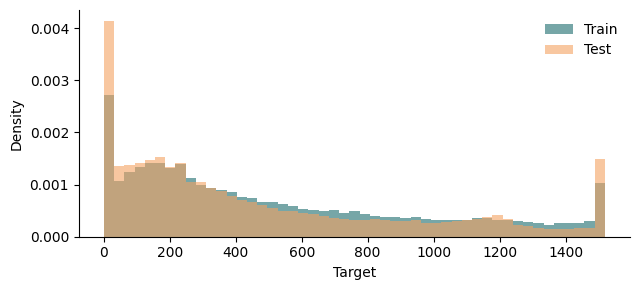

           train       test
count  60000.000  40000.000
mean     517.971    471.881
std      439.715    448.949
min        0.000      0.000
25%      160.675    119.515
50%      381.845    309.760
75%      806.262    738.948
max     1521.300   1524.420


In [6]:
# Step 4d: Target distribution in the training and test sets
# What : Define the plotting helpers and compare the target distribution of the two sets.
# Why  : Two different distributions explain why tree models extrapolate badly.

import matplotlib.pyplot as plt
def bar_chart(labels, values, ylabel, path, highlight=None, fmt='{:.1f}'):
    fig, ax = plt.subplots(figsize=(6.5, 3.2))
    colors = ['#F4A261' if i == highlight else '#1B6B6D' for i in range(len(values))]
    bars = ax.bar([str(l) for l in labels], values, color=colors)
    ax.bar_label(bars, labels=[fmt.format(v) for v in values], fontweight='bold', padding=2, fontsize=8 if len(values) > 7 else 10)
    ax.set_ylabel(ylabel); ax.set_ylim(0, max(values) * 1.2)
    ax.spines[['top', 'right']].set_visible(False)          # no top and right spines
    if len(values) > 7: ax.tick_params(axis='x', labelsize=7, rotation=30); plt.setp(ax.get_xticklabels(), ha='right')
    fig.tight_layout(); fig.savefig(path, dpi=300); plt.show()

import matplotlib.pyplot as plt
def nice(v, label):                                     # readable numbers on the bars
    v = np.asarray(v, dtype=float); m = np.nanmax(np.abs(v))
    return (v / 1e6, label + ' (million)', '{:.2f}') if m >= 1e6 else (v / 1e3, label + ' (thousand)', '{:.1f}') if m >= 1e4 else (v, label, '{:.2f}' if m < 100 else '{:.0f}')
ytr, yte = pd.Series(np.asarray(y_tr, dtype=float)), pd.Series(np.asarray(y_te, dtype=float)); BINARY = ytr.nunique() <= 2
print('train rows', len(ytr), 'test rows', len(yte), 'features', X_tr.shape[1])
if BINARY: print('positive share: train %.3f, test %.3f' % (ytr.mean(), yte.mean()))
else:
    fig, ax = plt.subplots(figsize=(6.5, 3)); lo, hi = min(ytr.quantile(.01), yte.quantile(.01)), max(ytr.quantile(.99), yte.quantile(.99)); bins = np.linspace(lo, hi, 50)
    ax.hist(ytr.clip(lo, hi), bins=bins, density=True, alpha=.6, color='#1B6B6D', label='Train'); ax.hist(yte.clip(lo, hi), bins=bins, density=True, alpha=.6, color='#F4A261', label='Test')
    ax.legend(frameon=False); ax.set_xlabel('Target'); ax.set_ylabel('Density'); ax.spines[['top', 'right']].set_visible(False); fig.tight_layout(); fig.savefig('report/fig_split_target.png', dpi=200); plt.show()
    print(pd.DataFrame({'train': ytr.describe(), 'test': yte.describe()}).round(3))

In [7]:
# Step 4e: Feature shift between the two sets
# What : Standardised mean difference of every feature between the training and the test
#        set.
# Check: A feature that shifts by more than 0.5 standard deviations is a risk and is stated
#        under Limitations.

A_, B_ = X_tr.astype(float), X_te.astype(float); sd = A_.std().replace(0, np.nan)
shift = ((B_.mean() - A_.mean()) / sd).abs().sort_values(ascending=False).rename('abs_standardised_mean_difference')
shift.to_csv('report/table_split_shift.csv'); display(shift.head(10).round(3).to_frame())
print('features whose test mean lies more than 0.5 training standard deviations away:', int((shift > 0.5).sum()), 'of', len(shift))

,abs_standardised_mean_difference
Itmp,1.828
w_mean1h,0.311
w_lag1,0.298
Wspd,0.290
Etmp,0.230
wdir_cos,0.177
p_mean1h,0.153
p_lag3,0.151
p_lag2,0.148
Pab1,0.146


features whose test mean lies more than 0.5 training standard deviations away: 1 of 17


In [8]:
# Step 4f: Feature shift after physical limits on temperature
# What : Mask temperatures outside physical limits, then recompute the standardised mean
#        difference.
# Why  : Extreme sensor errors in Etmp and Itmp can inflate the shift.
# Check: Compare with the table of Step 4e.

# Physical limits for temperature (removes extreme sensor errors)
A_df = train.copy()
B_df = test.copy()

# Set non-physical temperatures to NaN (ambient outside -40 to 60 C, internal outside -20 to 90 C)
for df in [A_df, B_df]:
    if 'Itmp' in df.columns:
        df.loc[(df['Itmp'] < -20) | (df['Itmp'] > 90), 'Itmp'] = np.nan
    if 'Etmp' in df.columns:
        df.loc[(df['Etmp'] < -40) | (df['Etmp'] > 60), 'Etmp'] = np.nan

# Recompute the SMD after applying the physical limits
A_clean = A_df[X_cols_temp].dropna()
B_clean = B_df[X_cols_temp].dropna()

sd = A_clean.std().replace(0, np.nan)
shift_corrected = ((B_clean.mean() - A_clean.mean()) / sd).abs().sort_values(ascending=False).rename('SMD_corrected')

print("--- SMD AFTER PHYSICAL LIMITS ---")
display(shift_corrected.head(10).round(3).to_frame())

--- SMD SAU KHI LỌC NGƯỠNG VẬT LÝ ---


,SMD_corrected
Etmp,3.297
Itmp,3.001
w_mean1h,0.299
w_lag1,0.287
Wspd,0.278
wdir_cos,0.166
p_mean1h,0.141
p_lag3,0.139
p_lag2,0.136
p_lag1,0.133


In [9]:
# Step 4g: Strength of each feature
# What : Rank correlation between each feature and the target on the training set.
# Why  : If one feature is nearly enough, a complex model will not beat it by much.
# Check: The strongest single feature is printed; a model must beat what that feature
#        already gives.

sig = A_.sample(min(len(A_), 20_000), random_state=0); ys = pd.Series(np.asarray(y_tr, dtype=float), index=X_tr.index).loc[sig.index]
strength = sig.corrwith(ys, method='spearman').abs().sort_values(ascending=False).rename('abs_rank_correlation_with_target')
strength.to_csv('report/table_feature_strength.csv'); display(strength.head(10).round(3).to_frame())
print('strongest single feature:', strength.index[0], round(float(strength.iloc[0]), 3), '-> a model must beat what this feature already gives')

,abs_rank_correlation_with_target
Patv,0.794
Wspd,0.783
p_mean1h,0.771
p_lag1,0.770
w_lag1,0.760
w_mean1h,0.760
p_lag2,0.749
p_lag3,0.725
p_lag6,0.647
Prtv,0.326


strongest single feature: Patv 0.794 -> a model must beat what this feature already gives


In [10]:
# Step 6a: Compare ten model families (RQ2)
# What : Train ten model families with five seeds on the same split, learning the 1-hour
#        change (delta) of power; score MAE, RMSE and R2 on the test set and MAE on
#        validation.
# Why  : Several families make the conclusion independent of one model type; five seeds give
#        a standard deviation.
# Check: A difference smaller than the standard deviation does not justify calling one model
#        better. Results are saved to report/table_rq2.csv.

import time
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, ElasticNet
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, HistGradientBoostingRegressor
from sklearn.neural_network import MLPRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from sklearn.metrics import mean_absolute_error as MAE, mean_squared_error as MSE, r2_score

sc = lambda m: make_pipeline(StandardScaler(), m)

# STANDARD MODEL CONFIGURATION
models = {
    # --- Group 3: Keep original standard L2 (Since library lacks native L1) ---
    'Ridge':          lambda s: sc(Ridge(alpha=100.0)),
    'Elastic Net':    lambda s: sc(ElasticNet(alpha=0.1, l1_ratio=0.5, max_iter=5000, random_state=s)),
    'k-NN':           lambda s: sc(KNeighborsRegressor(n_neighbors=25)),
    'Small MLP':      lambda s: sc(MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=500, alpha=0.01, early_stopping=True, random_state=s)),

    # --- Group 2: Traditional trees (Switch to standard native L1: absolute_error) ---
    'Decision Tree':  lambda s: DecisionTreeRegressor(max_depth=8, min_samples_leaf=30, criterion='absolute_error', random_state=s),
    'Random Forest':  lambda s: RandomForestRegressor(n_estimators=300, min_samples_leaf=15, criterion='absolute_error', n_jobs=-1, random_state=s),
    'Extra Trees':    lambda s: ExtraTreesRegressor(n_estimators=300, min_samples_leaf=15, criterion='absolute_error', n_jobs=-1, random_state=s),

    # --- Group 1: Modern Boosting (Switch to standard native L1: absolute_error) ---
    'HistGB-L1':      lambda s: HistGradientBoostingRegressor(loss='absolute_error', max_iter=300, learning_rate=0.03, min_samples_leaf=30, random_state=s),
    'LightGBM-L1':    lambda s: LGBMRegressor(objective='mean_absolute_error', n_estimators=600, learning_rate=0.01, num_leaves=15, subsample=0.7, colsample_bytree=0.7, random_state=s, verbose=-1),
    'XGBoost-L1':     lambda s: XGBRegressor(objective='reg:absoluteerror', n_estimators=600, learning_rate=0.01, max_depth=4, subsample=0.7, colsample_bytree=0.7, tree_method='hist', random_state=s),
}

# Utility function: Add predicted delta to current power to get absolute power (lower bound clipped to 0)
def predict_abs(m, d, cols=X_cols):
    return np.clip(d['Patv'].to_numpy() + m.predict(d[cols]), 0, None)

# Set Persistence baseline for comparison
naive = test[NAIVE]
rows, fitted = [['Persistence', MAE(y_te_abs, naive), 0, MSE(y_te_abs, naive) ** 0.5, r2_score(y_te_abs, naive), 0, MAE(val.y, val[NAIVE])]], {}

print("Training 10 model families on y_delta target (difference)...")
print("Note: Random Forest / Extra Trees (L1) group will take a long time to compute the median.")

for name, make in models.items():
    maes, rmses, r2s, secs, vmaes = [], [], [], [], []
    for seed in range(5): # Run 5 seeds to get standard deviation
        m = make(seed); t0 = time.perf_counter()

        # 100% of models must learn the difference (y_delta)
        m.fit(X_tr, train.y_delta)
        secs.append(time.perf_counter() - t0)

        # Restore to absolute power to score MAE/RMSE
        p_abs = predict_abs(m, test)
        maes.append(MAE(y_te_abs, p_abs))
        rmses.append(MSE(y_te_abs, p_abs) ** 0.5)
        r2s.append(r2_score(y_te_abs, p_abs))

        # Evaluate on Validation set to select model (prevent data leakage)
        vmaes.append(MAE(val.y, predict_abs(m, val)))

        fitted[name] = m

    rows.append([name, np.mean(maes), np.std(maes), np.mean(rmses), np.mean(r2s), np.mean(secs), np.mean(vmaes)])

# Export results to report
res = pd.DataFrame(rows, columns=['model', 'MAE', 'sd', 'RMSE', 'R2', 'train_s', 'val_MAE'])
res.to_csv('report/table_rq2.csv', index=False)
print("\n--- MODEL COMPARISON RESULTS (RQ2) ---")
print(res.drop(columns='train_s').round(4).to_string())

Training 10 model families on y_delta target (difference)...
Note: Random Forest / Extra Trees (L1) group will take a long time to compute the median.

--- MODEL COMPARISON RESULTS (RQ2) ---
            model       MAE      sd      RMSE      R2   val_MAE
0     Persistence  126.0744  0.0000  193.0715  0.8151  153.6257
1           Ridge  136.1247  0.0000  187.8948  0.8248  152.9657
2     Elastic Net  136.0420  0.0000  187.8337  0.8249  153.3462
3            k-NN  133.0063  0.0000  190.7762  0.8194  151.0812
4       Small MLP  137.4654  1.7855  192.7197  0.8157  149.6233
5   Decision Tree  132.0688  0.1767  198.7232  0.8041  151.4742
6   Random Forest  128.5261  0.1368  185.5126  0.8292  146.5116
7     Extra Trees  124.0699  0.0951  181.8444  0.8359  144.6805
8       HistGB-L1  124.5603  0.3974  183.1550  0.8336  144.1263
9     LightGBM-L1  122.2237  0.1122  181.5051  0.8365  143.7590
10     XGBoost-L1  122.5920  0.1009  182.0011  0.8357  144.2131


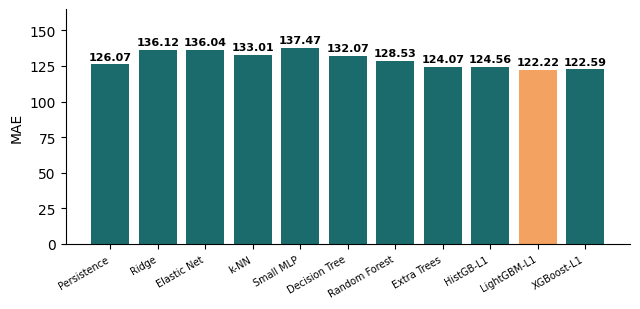

In [11]:
# Step 6a: Figure for RQ2
# What : Bar chart of the test MAE of all models; the best model is highlighted.
# Check: The numbers on the bars match report/table_rq2.csv.

import matplotlib.pyplot as plt
def bar_chart(labels, values, ylabel, path, highlight=None, fmt='{:.1f}'):
    fig, ax = plt.subplots(figsize=(6.5, 3.2))
    colors = ['#F4A261' if i == highlight else '#1B6B6D' for i in range(len(values))]
    bars = ax.bar([str(l) for l in labels], values, color=colors)
    ax.bar_label(bars, labels=[fmt.format(v) for v in values], fontweight='bold', padding=2, fontsize=8 if len(values) > 7 else 10)
    ax.set_ylabel(ylabel); ax.set_ylim(0, max(values) * 1.2)
    ax.spines[['top', 'right']].set_visible(False)          # no top and right spines
    if len(values) > 7: ax.tick_params(axis='x', labelsize=7, rotation=30); plt.setp(ax.get_xticklabels(), ha='right')
    fig.tight_layout(); fig.savefig(path, dpi=300); plt.show()

bar_chart(res.model, res.iloc[:, 1], res.columns[1], 'report/fig_rq2_models.png', highlight=int(res.iloc[:, 1].idxmin()), fmt='{:.2f}')

In [12]:
# Feasibility gate: keep or pivot the question
# What : Compare the best model (chosen on validation) with the Persistence reference and
#        print one of two verdicts.
# Why  : If the model does not beat the reference, the question is pivoted here instead of
#        tuning further.
# Check: The verdict and the numbers are saved to report/table_feasibility_gate.csv.

ref, cand = res.iloc[0], res.iloc[1:]
best_row = cand.sort_values('val_MAE').iloc[0]; best_model_name = best_row.model
skill = 100 * (1 - best_row.MAE / ref.MAE)

print('Reference %s: test MAE %.4f' % (ref.model, ref.MAE))
print('Best on validation: %s, test MAE %.4f | Improvement %.1f%%' % (best_model_name, best_row.MAE, skill))

verdict = 'GOOD: model clearly beats reference' if skill >= 2.0 else 'NONE: reference wins, pivot question'
print(verdict)
pd.Series({'reference_MAE': ref.MAE, 'best_model': best_model_name, 'best_MAE': best_row.MAE, 'improvement_pct': skill, 'verdict': verdict}).to_csv('report/table_feasibility_gate.csv')

Reference Persistence: test MAE 126.0744
Best on validation: LightGBM-L1, test MAE 122.2237 | Improvement 3.1%
GOOD: model clearly beats reference


In [13]:
# Step 6b-1: Cleaning ladder and unseen turbines (RQ3)
# What : Retrain all ten models at every stage of the cleaning ladder (raw, negative power
#        set to zero, unknown rows removed, abnormal rows removed) and score every stage on
#        the same test rows; then compare seen and unseen turbines.
# Why  : This is the main contribution; each report/table_rq3_*.csv supports one point of
#        the Results section.
# Check: Read each printed table and write one conclusion with numbers. Report unexpected
#        results as they are.

LADDER = {'0 raw values': dict(clip=False, unknown=False, abnormal=False), '1 + negative power set to zero': dict(unknown=False, abnormal=False),
          '2 + unknown rows removed': dict(abnormal=False), '3 + abnormal rows removed': dict()}
key = lambda d: pd.MultiIndex.from_arrays([d.TurbID, d.step]); E = key(test)

def y_true_target(d): k = pd.MultiIndex.from_arrays([d.TurbID, d.step + HORIZON]); return truth.Patv.reindex(k).clip(lower=0).to_numpy()

rows = []
for stage, kw in LADDER.items():
    t = table(base, **kw)
    A = cap(t[(t.Day <= D1) & ~t.TurbID.isin(UNSEEN)].dropna(subset=X_cols), 60_000)
    B = t.set_index(key(t)).reindex(E)
    ok = B[X_cols].notna().all(axis=1).to_numpy(); yt = y_true_target(test)[ok]
    own = cap(t[(t.Day > D2) & ~t.TurbID.isin(UNSEEN)].dropna(subset=X_cols), 40_000)

    A_delta = A.y - A.Patv

    for name, make in models.items():
        m = make(0).fit(A[X_cols], A_delta)
        mae_clean = MAE(yt, predict_abs(m, B.loc[ok]))
        mae_own = MAE(own.y, predict_abs(m, own))
        rows.append([stage, name, len(A), mae_clean, mae_own])

lad = pd.DataFrame(rows, columns=['cleaning_stage', 'model', 'train_rows', 'MAE_on_clean_targets', 'MAE_on_own_targets'])
tab = lad.pivot(index='cleaning_stage', columns='model', values='MAE_on_clean_targets')
tab['mean_on_clean'] = tab.mean(axis=1); tab['change_clean'] = tab['mean_on_clean'].diff()
tab['mean_on_own'] = lad.groupby('cleaning_stage').MAE_on_own_targets.mean()
tab.to_csv('report/table_rq3_cleaning_ladder.csv'); print(tab[['mean_on_clean', 'change_clean', 'mean_on_own']].round(2))

rows = [[name, MAE(y_te_abs, predict_abs(m, test)), MAE(test_unseen.y, predict_abs(m, test_unseen))] for name, m in fitted.items()]
rows.append(['Persistence', MAE(y_te_abs, test[NAIVE]), MAE(test_unseen.y, test_unseen[NAIVE])])
un = pd.DataFrame(rows, columns=['model', 'MAE_seen_turbines', 'MAE_unseen_turbines']); un['gap'] = un.MAE_unseen_turbines - un.MAE_seen_turbines
un.to_csv('report/table_rq3_unseen_turbines.csv', index=False); print(un.round(2))

model                           mean_on_clean  change_clean  mean_on_own
cleaning_stage                                                          
0 raw values                           129.77           NaN       102.00
1 + negative power set to zero         130.00          0.23       102.13
2 + unknown rows removed               130.39          0.39       130.39
3 + abnormal rows removed              129.83         -0.57       129.83
            model  MAE_seen_turbines  MAE_unseen_turbines    gap
0           Ridge             136.12               150.20  14.08
1     Elastic Net             136.04               149.59  13.55
2            k-NN             133.01               148.49  15.49
3       Small MLP             135.39               152.58  17.18
4   Decision Tree             132.16               149.19  17.03
5   Random Forest             128.49               145.57  17.08
6     Extra Trees             123.93               141.04  17.10
7       HistGB-L1             124.88      

In [14]:
# Step 6b-2: Cleaning ladder with fixed rows and five seeds
# What : For every ladder stage use the same fixed test row IDs, train LightGBM with five
#        seeds and compare with Persistence (MAE and skill score).
# Why  : Fixed rows make the stages comparable.
# Check: Results are saved to report/table_ladder_2x2_fixed_seeds.csv.

print("--- CLEANING LADDER 2x2 (FIXED ROW IDs & 5 SEEDS) ---")
key = lambda d: pd.MultiIndex.from_arrays([d.TurbID, d.step])
common_index = key(test) 

ladder_results = []
for stage, kw in LADDER.items():
    t_all = table(base, **kw)
    
    A_stage = cap(t_all[(t_all.Day <= D1) & ~t_all.TurbID.isin(UNSEEN)].dropna(subset=X_cols), 60_000)
    A_delta = A_stage.y - A_stage.Patv
    
    B_stage = t_all.set_index(key(t_all)).reindex(common_index).dropna(subset=X_cols + ['y'])
    
    stage_pers_mae = MAE(B_stage.y, B_stage['Patv'])
    
    # Train 5 seeds
    seed_maes = []
    for seed in range(5):
        m = LGBMRegressor(objective='mean_absolute_error', n_estimators=600, learning_rate=0.01, num_leaves=15, subsample=0.7, colsample_bytree=0.7, random_state=seed, verbose=-1)
        m.fit(A_stage[X_cols], A_delta)
        p_pred = np.clip(B_stage['Patv'].to_numpy() + m.predict(B_stage[X_cols]), 0, None)
        seed_maes.append(MAE(B_stage.y, p_pred))
    
    stage_model_mae = np.mean(seed_maes)
    ladder_results.append([stage, len(B_stage), stage_pers_mae, stage_model_mae])

df_ladder_fixed = pd.DataFrame(ladder_results, columns=['Stage', 'Fixed_Rows', 'Persistence_MAE', 'LightGBM_MAE'])
df_ladder_fixed['Skill_Score(%)'] = 100 * (1 - df_ladder_fixed['LightGBM_MAE'] / df_ladder_fixed['Persistence_MAE'])

display(df_ladder_fixed.round(3))
df_ladder_fixed.to_csv('report/table_ladder_2x2_fixed_seeds.csv', index=False)

--- CLEANING LADDER 2x2 (FIXED ROW IDs & 5 SEEDS) ---


,Stage,Fixed_Rows,Persistence_MAE,LightGBM_MAE,Skill_Score(%)
0,0 raw values,40000,126.102,122.987,2.470
1,1 + negative power set to zero,40000,126.074,122.950,2.478
2,2 + unknown rows removed,40000,126.074,122.595,2.760
3,3 + abnormal rows removed,40000,126.074,122.224,3.054


In [15]:
# Step 6c-1: Skill by wind-speed band
# What : MAE of the best model and of Persistence in four wind-speed bands, with the skill
#        score.
# Check: Results are saved to report/table_rq3_by_wind.csv.

p = predict_abs(fitted[best_model_name], test)

band = pd.cut(test.Wspd, [-1, 3, 7, 11, 100], labels=['below 3 m/s', '3 to 7 m/s', '7 to 11 m/s', 'above 11 m/s'])
wind = test.assign(err=np.abs(y_te_abs - p), err_naive=np.abs(y_te_abs - test[NAIVE]), band=band).groupby('band', observed=True).agg(rows=('y', 'size'), MAE=('err', 'mean'), MAE_persistence=('err_naive', 'mean'))
wind['skill_pct'] = 100 * (1 - wind.MAE / wind.MAE_persistence); wind.to_csv('report/table_rq3_by_wind.csv'); print(best_model_name); print(wind.round(2))

LightGBM-L1
               rows     MAE  MAE_persistence  skill_pct
band                                                   
below 3 m/s    8492   43.59            40.49      -7.65
3 to 7 m/s    21149  125.61           127.20       1.25
7 to 11 m/s    7797  197.65           216.81       8.84
above 11 m/s   2562  127.61           124.35      -2.62


In [17]:
# Step 6c-2: Operational test set
# What : Score LightGBM-L1 and Persistence on all later-period rows without the target_ok
#        filter.
# Why  : Simulates real operation where the target may itself be a bad record.

print("--- EVALUATION ON THE OPERATIONAL TEST SET ---")
# Use the whole late period without the target_ok filter (simulates real operation)
operational_late = clean[(clean.Day > D2) & ~clean.TurbID.isin(UNSEEN)]

# Drop only the rows made NaN by shifting; the valid flag is not used
test_op = operational_late.dropna(subset=X_cols + ['y']).sample(min(40_000, len(operational_late)), random_state=42)

# Score LightGBM-L1 (best model) and Persistence on the operational set
naive_op = test_op['Patv']
mae_pers_op = MAE(test_op.y, naive_op)

best_model = fitted['LightGBM-L1'] # best model from the fitted dictionary
p_abs_op = np.clip(test_op['Patv'].to_numpy() + best_model.predict(test_op[X_cols]), 0, None)
mae_model_op = MAE(test_op.y, p_abs_op)

print(f"Operational Persistence MAE: {mae_pers_op:.4f}")
print(f"Operational LightGBM-L1 MAE: {mae_model_op:.4f}")
print(f"Operational Skill Score: {100 * (1 - mae_model_op / mae_pers_op):.2f}%")

--- ĐÁNH GIÁ TRÊN TẬP TEST VẬN HÀNH THỰC TẾ ---
Operational Persistence MAE: 126.3579
Operational LightGBM-L1 MAE: 123.4037
Operational Skill Score: 2.34%


In [18]:
# Step 6c-3: Day-level bootstrap and Wilcoxon test
# What : Mean MAE per day, a 95% confidence interval for the skill score from a day-level
#        bootstrap, and a paired one-sided Wilcoxon test.
# Why  : Rows of the same day are correlated, so days are the resampling unit.

from scipy.stats import wilcoxon

# MAE per day (day-block bootstrap and Wilcoxon)
test_with_err = test.copy()
test_with_err['Err_Pers'] = np.abs(test.y - test['Patv'])
test_with_err['Err_LGBM'] = np.abs(test.y - np.clip(test['Patv'].to_numpy() + fitted['LightGBM-L1'].predict(test[X_cols]), 0, None))

# Mean MAE per day
daily_errors = test_with_err.groupby('Day')[['Err_Pers', 'Err_LGBM']].mean()

# 1. Block-bootstrap CI (resample by day)
np.random.seed(42)
n_days = len(daily_errors)
boot_skills = []
for _ in range(1000):
    sample_days = daily_errors.sample(n=n_days, replace=True)
    boot_mae_pers = sample_days['Err_Pers'].mean()
    boot_mae_lgbm = sample_days['Err_LGBM'].mean()
    boot_skills.append(100 * (1 - boot_mae_lgbm / boot_mae_pers))

print(f"LightGBM Skill Score (Bootstrap): {np.mean(boot_skills):.2f}%")
print(f"95% Confidence Interval: [{np.percentile(boot_skills, 2.5):.2f}%, {np.percentile(boot_skills, 97.5):.2f}%]")

# 2. Paired Wilcoxon test
stat, p_value = wilcoxon(daily_errors['Err_LGBM'], daily_errors['Err_Pers'], alternative='less')
print(f"Wilcoxon p-value: {p_value:.2e} -> {'SIGNIFICANT' if p_value < 0.05 else 'NOT SIGNIFICANT'}")

LightGBM Skill Score (Bootstrap): 2.57%
95% Confidence Interval: [-0.15%, 5.14%]
Wilcoxon p-value: 8.00e-02 -> NOT SIGNIFICANT


In [19]:
# Step 6c-4: Three folds of unseen turbines
# What : Hold out three different turbine clusters and score LightGBM-L1 against Persistence
#        on each.
# Why  : Checks that the unseen-turbine result does not depend on one particular choice of
#        turbines.

print("--- MULTI-FOLD UNSEEN TURBINES ---")
all_turbines = np.sort(base.TurbID.unique())

# Three different unseen-turbine clusters
unseen_folds = [
    set(all_turbines[0::3]), # Fold 1
    set(all_turbines[1::3]), # Fold 2
    set(all_turbines[2::3])  # Fold 3
]

fold_results = []
for i, unseen_set in enumerate(unseen_folds):
    # Test data of the corresponding fold
    fold_test = late[late.TurbID.isin(unseen_set)].dropna(subset=X_cols + ['y']).sample(min(20000, len(late)), random_state=42)
    
    pers_mae = MAE(fold_test.y, fold_test['Patv'])
    lgbm_mae = MAE(fold_test.y, np.clip(fold_test['Patv'].to_numpy() + fitted['LightGBM-L1'].predict(fold_test[X_cols]), 0, None))
    
    fold_results.append([f'Fold {i+1}', pers_mae, lgbm_mae, 100 * (1 - lgbm_mae / pers_mae)])

df_unseen_folds = pd.DataFrame(fold_results, columns=['Fold', 'Persistence_MAE', 'LightGBM_MAE', 'Skill_Score(%)'])
display(df_unseen_folds.round(3))

--- MULTI-FOLD UNSEEN TURBINES ---


,Fold,Persistence_MAE,LightGBM_MAE,Skill_Score(%)
0,Fold 1,133.172,129.564,2.710
1,Fold 2,127.361,123.447,3.073
2,Fold 3,131.518,127.504,3.052


In [27]:
# Step 6c-5: Day-level skill on the operational set
# What : Day-level skill score, bootstrap interval, Wilcoxon p-value and the share of days
#        on which LightGBM wins.

op = operational_late.dropna(subset=X_cols + ['y']).copy()
op['Err_Pers'] = (op.y - op.Patv).abs()
op['Err_LGBM'] = (op.y - np.clip(op.Patv.to_numpy() + best_model.predict(op[X_cols]), 0, None)).abs()
d = op.groupby('Day')[['Err_Pers', 'Err_LGBM']].mean()

rng = np.random.default_rng(42); sk = []
for _ in range(1000):
    s = d.iloc[rng.integers(0, len(d), len(d))]
    sk.append(100 * (1 - s.Err_LGBM.mean() / s.Err_Pers.mean()))
print('Days:', len(d), '| rows:', len(op))
print('Skill score: %.2f%%' % (100 * (1 - d.Err_LGBM.mean() / d.Err_Pers.mean())))
print('CI 95%%: [%.2f%%, %.2f%%]' % tuple(np.percentile(sk, [2.5, 97.5])))
print('Wilcoxon p =', wilcoxon(d.Err_LGBM, d.Err_Pers, alternative='less').pvalue)
d['skill_day'] = 100 * (1 - d.Err_LGBM / d.Err_Pers)
print('Days LGBM wins: %.1f%%' % (100 * (d.skill_day > 0).mean()))
print(d.skill_day.describe().round(2))

Số ngày: 49 | số dòng: 159542
Skill điểm: 2.04%
CI 95%: [-0.64%, 4.35%]
Wilcoxon p = 0.12746078130060734
Ngày LGBM thắng: 55.1%
count    49.00
mean     -1.89
std      13.78
min     -48.99
25%      -6.36
50%       1.51
75%       7.48
max      22.56
Name: skill_day, dtype: float64


In [28]:
# Step 6c-6: Five-seed retraining with day-level statistics
# What : Retrain LightGBM-L1 with five seeds, keep per-row errors, check consistency with
#        the res table, then compute day-level skill, bootstrap interval and Wilcoxon
#        p-value.
# Check: The mean MAE over five seeds matches the LightGBM-L1 row of the res table.

from scipy.stats import wilcoxon

mk = models['LightGBM-L1']                      # same configuration as RQ2 (random_state = seed)
t = test.copy()
t['Err_Pers'] = (t.y - t.Patv).abs()

# 1. Retrain with 5 seeds and keep the per-row error of each seed
seed_err = []
for s in range(5):
    m = mk(s).fit(X_tr, train.y_delta)
    p = np.clip(t.Patv.to_numpy() + m.predict(t[X_cols]), 0, None)
    seed_err.append(np.abs(t.y.to_numpy() - p))
seed_err = np.array(seed_err)                   # shape (5, n_rows)
t['Err_LGBM'] = seed_err.mean(axis=0)           # mean error over 5 seeds

# 2. Check consistency with the res table (row level)
mae_seed = seed_err.mean(axis=1)
mae_pers = t.Err_Pers.mean()
skill_seed = 100 * (1 - mae_seed / mae_pers)
print('Mean LGBM MAE over 5 seeds: %.4f (sd %.4f) | res: %.4f' % (
      mae_seed.mean(), mae_seed.std(), res.loc[res.model == 'LightGBM-L1', 'MAE'].iloc[0]))
print('Row-level skill: %.2f%% (per seed: %s)' % (skill_seed.mean(), np.round(skill_seed, 2)))

# 3. Aggregate by day, then day-level bootstrap and Wilcoxon
d = t.groupby('Day')[['Err_Pers', 'Err_LGBM']].mean()
point = 100 * (1 - d.Err_LGBM.mean() / d.Err_Pers.mean())

rng = np.random.default_rng(42); sk = []
for _ in range(1000):
    s_ = d.iloc[rng.integers(0, len(d), len(d))]
    sk.append(100 * (1 - s_.Err_LGBM.mean() / s_.Err_Pers.mean()))
lo, hi = np.percentile(sk, [2.5, 97.5])
p_val = wilcoxon(d.Err_LGBM, d.Err_Pers, alternative='less').pvalue

print('Days: %d | rows: %d' % (len(d), len(t)))
print('Day-level skill (point): %.2f%% | 95%% CI: [%.2f%%, %.2f%%] | Wilcoxon p = %.3f' % (point, lo, hi, p_val))
print('Days LGBM wins: %.1f%%' % (100 * ((d.Err_Pers - d.Err_LGBM) > 0).mean()))

MAE LGBM trung bình 5 seed: 122.2237 (sd 0.1122) | res: 122.2237
Skill mức dòng: 3.05% (từng seed: [2.99 3.13 3.18 3.04 2.94])
Số ngày: 49 | số dòng: 40000
Skill theo ngày (điểm): 2.68% | CI 95%: [0.03%, 5.07%] | Wilcoxon p = 0.071
Ngày LGBM thắng: 57.1%


In [29]:
# Step 6c-7: Day-block bootstrap of the row-level skill
# What : Resample days with replacement (5000 times) and recompute the row-level skill,
#        weighted by the number of rows per day.
# Check: The point estimate equals the row-level skill printed in Step 6c-6.

# Day-block bootstrap for the ROW-LEVEL skill (weighted by rows per day)
g = t.groupby('Day').agg(sum_p=('Err_Pers', 'sum'), sum_l=('Err_LGBM', 'sum'), n=('Err_Pers', 'size'))
S_p, S_l = g.sum_p.to_numpy(), g.sum_l.to_numpy()

point_row = 100 * (1 - S_l.sum() / S_p.sum())          # should equal 3.05%

rng_r = np.random.default_rng(42)
idx = rng_r.integers(0, len(g), size=(5000, len(g)))   # 5000 resamples of 49 days with replacement
boot_row = 100 * (1 - S_l[idx].sum(axis=1) / S_p[idx].sum(axis=1))

lo_r, hi_r = np.percentile(boot_row, [2.5, 97.5])
p_boot = (boot_row <= 0).mean()                         # one-sided bootstrap p: share of resamples with skill <= 0

print('Row-level skill (point): %.2f%%' % point_row)
print('95%% CI (day-block bootstrap): [%.2f%%, %.2f%%]' % (lo_r, hi_r))
print('P(skill <= 0) theo bootstrap: %.4f' % p_boot)
print('P(skill < 2%%) theo bootstrap: %.3f' % (boot_row < 2.0).mean())
print('Days: %d | rows: %d' % (len(g), int(g.n.sum())))

Skill mức dòng (điểm): 3.05%
CI 95% (block-bootstrap theo ngày): [0.73%, 5.38%]
P(skill <= 0) theo bootstrap: 0.0062
P(skill < 2%) theo bootstrap: 0.189
Số ngày: 49 | số dòng: 40000


In [30]:
# Step 6c-8: Skill against a stronger baseline
# What : Compare LightGBM-L1 with the mean of the last hour (p_mean1h) using the same day-
#        block bootstrap.
# Why  : Persistence is a weak reference; this shows whether the model adds value over a
#        smoothed one.

t['Err_Strong'] = (t.y - t.p_mean1h).abs()
g2 = t.groupby('Day').agg(sp=('Err_Strong', 'sum'), sl=('Err_LGBM', 'sum'))
Sp, Sl = g2.sp.to_numpy(), g2.sl.to_numpy()
rng2 = np.random.default_rng(42)
ix = rng2.integers(0, len(g2), size=(5000, len(g2)))
bs = 100 * (1 - Sl[ix].sum(1) / Sp[ix].sum(1))
print('Skill vs p_mean1h: %.2f%% | CI95: [%.2f, %.2f] | P(<=0) = %.4f' % (
      100 * (1 - Sl.sum() / Sp.sum()), *np.percentile(bs, [2.5, 97.5]), (bs <= 0).mean()))

Skill so với p_mean1h: 10.09% | CI95: [6.42, 13.64] | P(<=0) = 0.0000


report\table_rq3_by_wind.csv (4, 5)


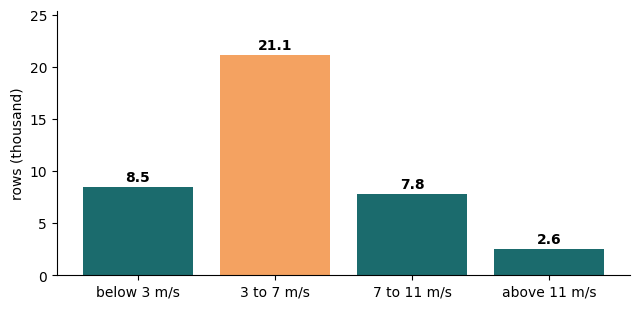

report\table_rq3_cleaning_ladder.csv (4, 14)


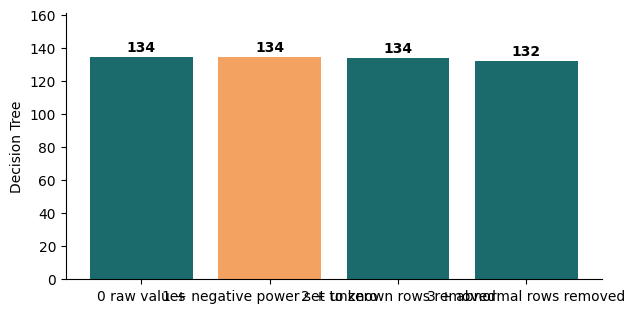

report\table_rq3_unseen_turbines.csv (11, 4)


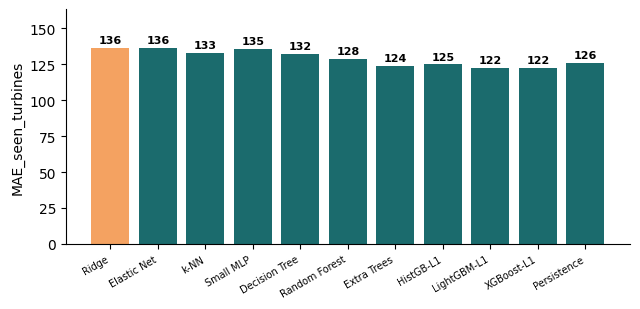

In [20]:
# Figures for RQ3 (automatic)
# What : For every report/table_rq3_*.csv with a small numeric table, draw a bar chart with
#        bar_chart().
# Check: One idea per figure, English labels, bold numbers on the bars.

import glob
for f in sorted(glob.glob('report/table_rq3_*.csv')):
    t = pd.read_csv(f); numc = [c for c in t.columns[1:] if pd.api.types.is_numeric_dtype(t[c])]
    print(f, t.shape)
    if 2 <= len(t) <= 14 and numc and t[numc[0]].notna().all() and t[numc[0]].min() >= 0 and t[numc[0]].max() > 0:
        v, lab, fm = nice(t[numc[0]], numc[0]); bar_chart(t.iloc[:, 0].astype(str), v, lab, f.replace('table_', 'fig_').replace('.csv', '.png'), highlight=int(v.argmax()), fmt=fm)

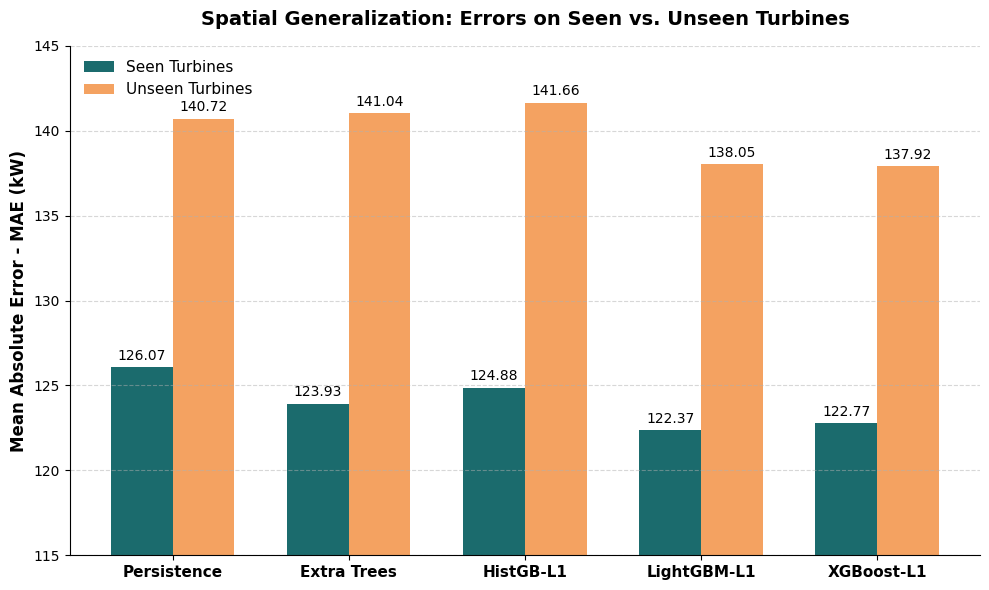

In [21]:
# Figure: seen versus unseen turbines (17-feature run)
# What : Grouped bar chart of the MAE on seen and unseen turbines. The MAE values are typed
#        in by hand from the 17-feature results.
# Check: Update the values if the experiment is rerun.

import matplotlib.pyplot as plt
import numpy as np

# 1. Data from Table V (17 columns) for unseen turbines (RQ3c)
labels = ['Persistence', 'Extra Trees', 'HistGB-L1', 'LightGBM-L1', 'XGBoost-L1']
seen_mae = [126.07, 123.93, 124.88, 122.37, 122.77]
unseen_mae = [140.72, 141.04, 141.66, 138.05, 137.92]

x = np.arange(len(labels))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))

rects1 = ax.bar(x - width/2, seen_mae, width, label='Seen Turbines', color='#1B6B6D')
rects2 = ax.bar(x + width/2, unseen_mae, width, label='Unseen Turbines', color='#F4A261')

ax.set_ylabel('Mean Absolute Error - MAE (kW)', fontsize=12, fontweight='bold')
ax.set_title('Spatial Generalization: Errors on Seen vs. Unseen Turbines', fontsize=14, fontweight='bold', pad=15)
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=11, fontweight='bold')
ax.legend(frameon=False, fontsize=11, loc='upper left')
ax.set_ylim(115, 145)
ax.bar_label(rects1, padding=3, fmt='%.2f', fontsize=10)
ax.bar_label(rects2, padding=3, fmt='%.2f', fontsize=10)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(axis='y', linestyle='--', alpha=0.5)

fig.tight_layout()
plt.savefig('improved_unseen_turbines.png', dpi=300)
plt.show()

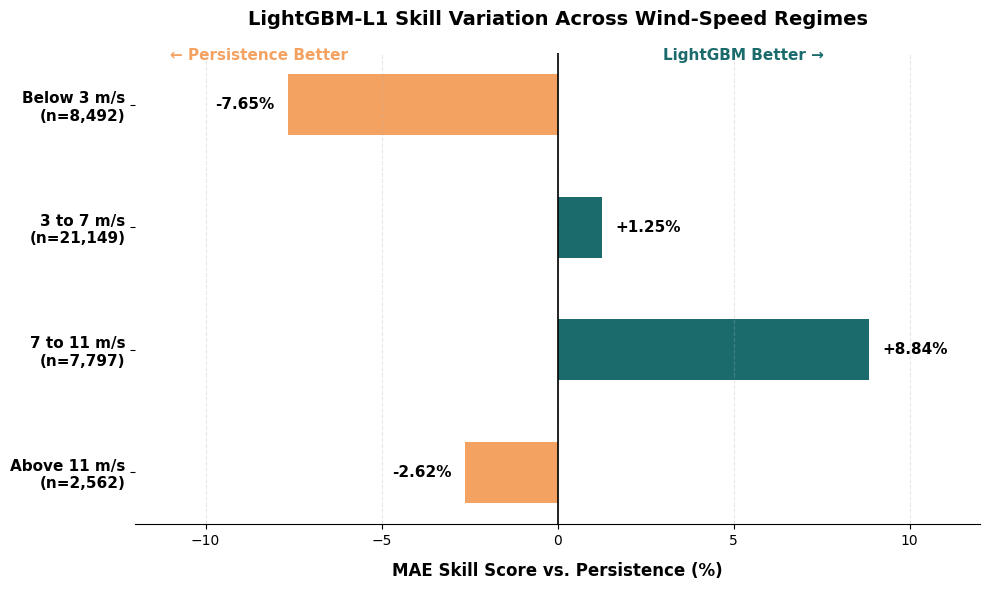

In [1]:
# Figure: LightGBM-L1 skill by wind-speed band (17-feature run)
# What : Horizontal bar chart of the skill score against Persistence in four wind-speed
#        bands. The values are typed in by hand.
# Check: Update the values if the experiment is rerun.

import matplotlib.pyplot as plt
import numpy as np

# 1. Data from the 17-feature model results across wind-speed bands
labels = ['Below 3 m/s\n(n=8,492)', '3 to 7 m/s\n(n=21,149)', '7 to 11 m/s\n(n=7,797)', 'Above 11 m/s\n(n=2,562)']
skills = [-7.65, 1.25, 8.84, -2.62]

# Colors: Negative (worse than persistence) in orange, Positive (better) in teal
colors = ['#F4A261' if val < 0 else '#1B6B6D' for val in skills]

fig, ax = plt.subplots(figsize=(10, 6))

# Horizontal bar chart
y_pos = np.arange(len(labels))
bars = ax.barh(y_pos, skills, color=colors, height=0.5)

# 2. Axis refinement and vertical zero-line
ax.axvline(0, color='black', linewidth=1.2)
ax.set_yticks(y_pos)
ax.set_yticklabels(labels, fontsize=11, fontweight='bold')
ax.invert_yaxis()  # Top-down orientation
ax.set_xlabel('MAE Skill Score vs. Persistence (%)', fontsize=12, fontweight='bold', labelpad=10)
ax.set_title('LightGBM-L1 Skill Variation Across Wind-Speed Regimes', fontsize=14, fontweight='bold', pad=20)

# Set symmetric limits for clarity
ax.set_xlim(-12, 12)

# 3. Directional annotations for intuitive readability
ax.text(-11, -0.4, '← Persistence Better', fontsize=11, color='#F4A261', fontweight='bold', va='center')
ax.text(3, -0.4, 'LightGBM Better →', fontsize=11, color='#1B6B6D', fontweight='bold', va='center')

# 4. Data labels on each bar with explicit formatting
for i, bar in enumerate(bars):
    val = skills[i]
    text = f"+{val:.2f}%" if val > 0 else f"{val:.2f}%"
    
    if val < 0:
        ax.text(val - 0.4, bar.get_y() + bar.get_height()/2, text, 
                va='center', ha='right', fontsize=11, fontweight='bold')
    else:
        ax.text(val + 0.4, bar.get_y() + bar.get_height()/2, text, 
                va='center', ha='left', fontsize=11, fontweight='bold')

# 5. Clean aesthetic (Academic Q1 style)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.grid(axis='x', linestyle='--', alpha=0.3)

fig.tight_layout()
plt.savefig('report/fig_rq3_by_wind_en.pdf', dpi=300)
plt.show()

In [ ]:
# Figure: model comparison from the results table
# What : Horizontal bar chart of the MAE of every model with a dashed line at the
#        Persistence MAE; reads res or report/table_rq2.csv.
# Check: Saved as report/fig_model_comparison.png and .pdf.

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Load actual experimental results from Notebook B, cell 14.
if "res" in globals() and isinstance(res, pd.DataFrame):
    plot_df = res.copy()
else:
    result_path = Path("report/table_rq2.csv")
    if not result_path.exists():
        raise FileNotFoundError(
            "Cannot find report/table_rq2.csv. "
            "Run Notebook B cell 14 first."
        )
    plot_df = pd.read_csv(result_path)

# 2. Validate the required columns.
required = {"model", "MAE"}
missing = required - set(plot_df.columns)

if missing:
    raise ValueError(
        f"Missing columns in experimental results: {sorted(missing)}"
    )

plot_df = plot_df[["model", "MAE"]].copy()
plot_df["MAE"] = pd.to_numeric(plot_df["MAE"], errors="raise")

if plot_df.empty or plot_df["MAE"].isna().any():
    raise ValueError("The model results are empty or contain missing MAE.")

if plot_df["model"].duplicated().any():
    raise ValueError("Duplicate model names found in the result table.")

# 3. Identify the Persistence baseline and best predictive model.
is_persistence = (
    plot_df["model"].astype(str).str.strip().str.casefold()
    == "persistence"
)

if is_persistence.sum() != 1:
    raise ValueError(
        "Expected exactly one Persistence baseline in table_rq2.csv."
    )

persistence_mae = plot_df.loc[is_persistence, "MAE"].iloc[0]

candidates = plot_df.loc[~is_persistence]
if candidates.empty:
    raise ValueError("No predictive models found.")

best_model = candidates.loc[candidates["MAE"].idxmin(), "model"]

# 4. Sort models from lowest to highest MAE.
plot_df = plot_df.sort_values("MAE", ascending=True).reset_index(drop=True)

# Highlight the best predictive model and the Persistence baseline.
colors = []
for _, row in plot_df.iterrows():
    if row["model"] == best_model:
        colors.append("#E99450")
    elif str(row["model"]).strip().casefold() == "persistence":
        colors.append("#4C5B70")
    else:
        colors.append("#2A807E")

# 5. Draw the horizontal bar chart.
fig, ax = plt.subplots(figsize=(8.5, 4.3))

# Vertical reference line at the measured Persistence MAE.
ax.set_axisbelow(True)
ax.grid(axis="x", alpha=0.22, zorder=0)
ax.axvline(
    persistence_mae,
    linestyle="--",
    linewidth=1.5,
    color="#4C5B70",
    zorder=1
)

bars = ax.barh(
    plot_df["model"],
    plot_df["MAE"],
    color=colors,
    height=0.68,
    zorder=2
)

# Annotate each bar with the actual MAE.
offset = plot_df["MAE"].max() * 0.006

for bar, value in zip(bars, plot_df["MAE"]):
    ax.text(
        value + offset,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.2f}",
        va="center",
        ha="left",
        fontsize=9
    )

ax.invert_yaxis()
ax.set_xlabel("Mean absolute error (kW)")
ax.set_ylabel("")
ax.set_xlim(0, plot_df["MAE"].max() * 1.10)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()

# 6. Export PNG and PDF.
output_dir = Path("report")
output_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    output_dir / "fig_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
fig.savefig(
    output_dir / "fig_model_comparison.pdf",
    bbox_inches="tight"
)

plt.show()

print(f"Best predictive model: {best_model}")
print(f"Persistence MAE: {persistence_mae:.4f} kW")
print("Saved figures to report/fig_model_comparison.png and .pdf")

In [ ]:
# Figure: cleaning ladder from the results table
# What : Line chart of Persistence and LightGBM MAE across the cleaning stages; reads
#        df_ladder_fixed or report/table_ladder_2x2_fixed_seeds.csv.
# Check: Saved as report/fig_cleaning_ladder.png and .pdf.

from pathlib import Path
import re
import textwrap

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Get experimental results generated by cell 21.
#    If the DataFrame is unavailable, load the saved experimental output.
if "df_ladder_fixed" in globals():
    plot_df = df_ladder_fixed.copy()
else:
    result_path = Path("report/table_ladder_2x2_fixed_seeds.csv")
    if not result_path.exists():
        raise FileNotFoundError(
            f"Missing experimental results: {result_path}. "
            "Run Notebook B cell 21 first."
        )
    plot_df = pd.read_csv(result_path)

# 2. Validate the columns required for plotting.
required = {
    "Stage", "Persistence_MAE", "LightGBM_MAE"
}
missing = required.difference(plot_df.columns)

if missing:
    raise ValueError(f"Missing required columns: {sorted(missing)}")

plot_df = plot_df.copy()

for col in ["Persistence_MAE", "LightGBM_MAE"]:
    plot_df[col] = pd.to_numeric(plot_df[col], errors="raise")

if (
    plot_df.empty
    or plot_df[["Persistence_MAE", "LightGBM_MAE"]]
       .isna().any().any()
):
    raise ValueError("Experimental results are empty or contain missing MAE.")

# Preserve the order defined by the experiment, if available.
if "LADDER" in globals():
    stage_order = [
        stage for stage in LADDER
        if stage in plot_df["Stage"].astype(str).tolist()
    ]
    if stage_order:
        plot_df = (
            plot_df.set_index("Stage")
            .loc[stage_order]
            .reset_index()
        )

# Generate display labels from the actual stage names.
def format_stage(stage):
    label = re.sub(r"^\d+\s*", "", str(stage))
    label = re.sub(r"^\+\s*", "", label)
    return "\n".join(textwrap.wrap(label, width=19))

labels = [format_stage(s) for s in plot_df["Stage"]]
x = np.arange(len(plot_df))

persistence = plot_df["Persistence_MAE"].to_numpy()
lightgbm = plot_df["LightGBM_MAE"].to_numpy()

# 3. Plot the measured MAE values.
fig, ax = plt.subplots(figsize=(6.5, 3.4))

ax.plot(
    x, persistence,
    marker="o", linewidth=2,
    label="Persistence"
)

ax.plot(
    x, lightgbm,
    marker="o", linewidth=2,
    label="LightGBM-L1"
)

# Annotate the actual LightGBM results, not manually entered values.
for xi, yi in zip(x, lightgbm):
    ax.annotate(
        f"{yi:.2f}",
        xy=(xi, yi),
        xytext=(0, -14),
        textcoords="offset points",
        ha="center",
        va="top",
        fontsize=8
    )

# Scale the vertical axis from the observed results.
all_values = np.concatenate([persistence, lightgbm])
y_min, y_max = all_values.min(), all_values.max()
margin = max((y_max - y_min) * 0.15, 0.25)

ax.set_ylim(y_min - margin, y_max + margin)
ax.set_ylabel("MAE (kW)")
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=8)
ax.grid(axis="y", alpha=0.25)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(frameon=False)

fig.tight_layout()

# 4. Export the figure.
output_dir = Path("report")
output_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    output_dir / "fig_cleaning_ladder.png",
    dpi=300,
    bbox_inches="tight"
)
fig.savefig(
    output_dir / "fig_cleaning_ladder.pdf",
    bbox_inches="tight"
)

plt.show()

In [ ]:
# Figure: generalisation to unseen turbines and wind-speed skill
# What : Combined figure from the unseen-turbine table (un) and the wind-band table (wind);
#        reads the CSV files if the DataFrames are missing.
# Check: Saved as report/fig_generalization_wind.png and .pdf.

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# 1. Load actual experimental results
#    Notebook B cell 20: un
#    Notebook B cell 23: wind
#    CSV files are used if the DataFrames are unavailable.
# ============================================================

def load_results(variable_name, csv_path):
    df = globals().get(variable_name)

    if isinstance(df, pd.DataFrame):
        return df.copy()

    path = Path(csv_path)
    if not path.exists():
        raise FileNotFoundError(
            f"Missing {path}. Run the corresponding experiment cell first."
        )

    return pd.read_csv(path)


holdout_df = load_results(
    "un",
    "report/table_rq3_unseen_turbines.csv"
)

wind_df = load_results(
    "wind",
    "report/table_rq3_by_wind.csv"
)

# ============================================================
# 2. Validate and prepare turbine-holdout results
# ============================================================

required_holdout = {
    "model",
    "MAE_seen_turbines",
    "MAE_unseen_turbines"
}

missing = required_holdout - set(holdout_df.columns)
if missing:
    raise ValueError(
        f"Missing columns in turbine-holdout results: {sorted(missing)}"
    )

holdout_df["model"] = holdout_df["model"].astype(str).str.strip()

for col in ["MAE_seen_turbines", "MAE_unseen_turbines"]:
    holdout_df[col] = pd.to_numeric(
        holdout_df[col], errors="raise"
    )

if holdout_df["model"].duplicated().any():
    raise ValueError("Duplicate model names in turbine-holdout results.")

# These names select the five model families displayed in the
# supplied figure. All plotted metrics come from experimental results.
model_order = [
    "Persistence",
    "Extra Trees",
    "HistGB-L1",
    "LightGBM-L1",
    "XGBoost-L1"
]

available = set(holdout_df["model"])
missing_models = set(model_order) - available

if missing_models:
    raise ValueError(
        "The holdout results do not contain these models: "
        f"{sorted(missing_models)}"
    )

holdout_df = (
    holdout_df.set_index("model")
    .loc[model_order]
    .reset_index()
)

# ============================================================
# 3. Validate and prepare wind-speed-band results
# ============================================================

if "band" not in wind_df.columns:
    wind_df = wind_df.rename_axis("band").reset_index()

if "skill_pct" not in wind_df.columns:
    if {"MAE", "MAE_persistence"}.issubset(wind_df.columns):
        wind_df["skill_pct"] = 100 * (
            1 - wind_df["MAE"] / wind_df["MAE_persistence"]
        )
    else:
        raise ValueError(
            "Wind results require skill_pct or both MAE and "
            "MAE_persistence columns."
        )

wind_df["skill_pct"] = pd.to_numeric(
    wind_df["skill_pct"], errors="raise"
)

if wind_df.empty or wind_df["skill_pct"].isna().any():
    raise ValueError("Wind-speed results are empty or contain missing values.")

def format_band(value):
    text = str(value).strip()
    mapping = {
        "below 3 m/s": "< 3 m/s",
        "3 to 7 m/s": "3-7 m/s",
        "7 to 11 m/s": "7-11 m/s",
        "above 11 m/s": "> 11 m/s"
    }
    return mapping.get(text.lower(), text)

wind_df["band_label"] = wind_df["band"].map(format_band)

# ============================================================
# 4. Draw the combined figure
# ============================================================

COLOR_SEEN = "#287F7B"
COLOR_UNSEEN = "#EE974A"

fig, (ax1, ax2) = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(14, 4.8),
    gridspec_kw={"width_ratios": [1.2, 1]},
)

# ------------------------------------------------------------
# Left panel: Turbine holdout
# ------------------------------------------------------------

y = np.arange(len(holdout_df))
bar_height = 0.32

seen_values = holdout_df["MAE_seen_turbines"].to_numpy()
unseen_values = holdout_df["MAE_unseen_turbines"].to_numpy()

ax1.set_axisbelow(True)
ax1.grid(axis="x", alpha=0.22)

ax1.barh(
    y - bar_height / 2,
    seen_values,
    height=bar_height,
    color=COLOR_SEEN,
    label="Seen",
    zorder=3,
)

unseen_bars = ax1.barh(
    y + bar_height / 2,
    unseen_values,
    height=bar_height,
    color=COLOR_UNSEEN,
    label="Unseen",
    zorder=3,
)

ax1.set_yticks(y)
ax1.set_yticklabels(holdout_df["model"])
ax1.invert_yaxis()
ax1.set_title("Turbine holdout", fontweight="bold", pad=10)
ax1.set_xlabel("MAE (kW)")

# Label the unseen-turbine MAE values from the results.
for bar, value in zip(unseen_bars, unseen_values):
    ax1.annotate(
        f"{value:.1f}",
        xy=(value, bar.get_y() + bar.get_height() / 2),
        xytext=(5, 0),
        textcoords="offset points",
        ha="left",
        va="center",
        fontsize=9,
    )

# Derive the viewing range from the actual measurements.
all_mae = np.concatenate([seen_values, unseen_values])
xmin = np.floor((all_mae.min() - 10) / 10) * 10
xmax = np.ceil((all_mae.max() + 7) / 10) * 10
ax1.set_xlim(xmin, xmax)

ax1.legend(
    frameon=False,
    ncol=2,
    loc="lower center",
    bbox_to_anchor=(0.70, 0.015),
)

ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)
ax1.tick_params(axis="y", length=0)

# ------------------------------------------------------------
# Right panel: Skill by wind-speed band
# ------------------------------------------------------------

skills = wind_df["skill_pct"].to_numpy()
y_band = np.arange(len(wind_df))

colors = [
    COLOR_SEEN if value >= 0 else COLOR_UNSEEN
    for value in skills
]

ax2.set_axisbelow(True)
ax2.grid(axis="x", alpha=0.22)

bars = ax2.barh(
    y_band,
    skills,
    color=colors,
    height=0.52,
    zorder=3,
)

ax2.axvline(0, color="#4C5B70", linewidth=1.2, zorder=2)

ax2.set_yticks(y_band)
ax2.set_yticklabels(wind_df["band_label"])
ax2.invert_yaxis()
ax2.set_title("Wind-speed bands", fontweight="bold", pad=10)
ax2.set_xlabel("Skill vs persistence (%)")

# Derive symmetric limits from the measured skill scores.
max_abs_skill = np.max(np.abs(skills))
x_limit = max(1.0, np.ceil((max_abs_skill + 1) / 2) * 2)
ax2.set_xlim(-x_limit, x_limit)

# Annotate each bar using its actual value.
for bar, value in zip(bars, skills):
    label = f"{value:+.2f}"
    center_y = bar.get_y() + bar.get_height() / 2

    if value < 0:
        ax2.text(
            value / 2,
            center_y,
            label,
            ha="center",
            va="center",
            fontsize=9,
        )
    else:
        ax2.annotate(
            label,
            xy=(value, center_y),
            xytext=(5, 0),
            textcoords="offset points",
            ha="left",
            va="center",
            fontsize=9,
        )

ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)
ax2.spines["left"].set_visible(False)
ax2.tick_params(axis="y", length=0)

# ============================================================
# 5. Export PDF and PNG
# ============================================================

output_dir = Path("report")
output_dir.mkdir(parents=True, exist_ok=True)

fig.tight_layout()

fig.savefig(
    output_dir / "fig_generalization_wind.pdf",
    bbox_inches="tight",
)

fig.savefig(
    output_dir / "fig_generalization_wind.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("Saved:")
print(output_dir / "fig_generalization_wind.pdf")
print(output_dir / "fig_generalization_wind.png")

In [24]:
# Test cases and diagnosis
# What : Automatic checks of the outputs of this notebook and a list of the files in
#        report/.
# Check: All asserts pass and 'Notebook B: all checks passed' is printed.

assert os.path.exists('report/table_rq2.csv') and os.path.exists('report/params_best.json')
assert len(glob.glob('report/table_rq3_*.csv')) >= 2, 'RQ3 tables missing'
if not res.iloc[1:, 1].min() <= res.iloc[0, 1]: print('WARNING: no model beats the simple reference, check features and split, then report it')
print(sorted(os.path.basename(f) for f in glob.glob('report/*')))
print('Notebook B: all checks passed')

['fig_eda_by_group.png', 'fig_eda_correlation.png', 'fig_eda_distributions.png', 'fig_eda_heatmap.png', 'fig_eda_missing.png', 'fig_eda_target.png', 'fig_horizon_spaghetti_all10_en.png', 'fig_horizon_spaghetti_en.png', 'fig_horizon_sweep_lines.png', 'fig_horizon_sweep_multiline.png', 'fig_q2.png', 'fig_q3.png', 'fig_q5.png', 'fig_q7.png', 'fig_q8.png', 'fig_rq1.png', 'fig_rq2_models.png', 'fig_rq3_by_wind.png', 'fig_rq3_by_wind_academic.png', 'fig_rq3_by_wind_en.png', 'fig_rq3_by_wind_improved.png', 'fig_rq3_cleaning_ladder.png', 'fig_rq3_unseen_turbines.png', 'fig_split_target.png', 'params_best.json', 'table_cleaning_log.csv', 'table_data_dictionary.csv', 'table_eda_by_group.csv', 'table_eda_correlation.csv', 'table_feasibility_gate.csv', 'table_feature_strength.csv', 'table_horizon_sweep_all_models.csv', 'table_horizon_sweep_all_models_5seeds.csv', 'table_ladder_2x2_fixed.csv', 'table_ladder_2x2_fixed_seeds.csv', 'table_learning_curve.csv', 'table_numeric_summary.csv', 'table_outlie